# Regressão salarial: tendências e limites

Radar de Carreira em TI. Grupo 12. CESAR School. Etapa 04. 19 de outubro de 2026.

**Pergunta:** como o salário mensal real de admissão se relaciona com idade, jornada, cargo, UF e escolaridade, e quanto modelos lineares simples explicam em comparação com uma referência constante?

Somente Novo CAGED MOV, jan-mar/2025; salários a preços de mar/2025. Não representa o mercado atual de 2026, salário júnior ou crescimento individual de carreira. Nenhuma resposta G12 é usada.

## Protocolo definido antes do teste

1. Admissões com `salario_valido=True`, preservando todos os valores elegíveis, inclusive caudas.
2. Validação interna: ajustar em janeiro e avaliar em fevereiro; escolher menor MAE, com preferência por simplicidade no empate.
3. Reajustar os três modelos em janeiro-fevereiro. Março é reservado para avaliação final, sem nova escolha ou ajuste.
4. Comparar mediana do treino, regressão linear de idade e regressão linear múltipla com Ridge (`alpha=10`, fixo).
5. Imputação, escala, categorias e coeficientes aprendidos somente no treino. Nenhuma variável derivada do salário entra como preditor.

**Resíduo = observado − previsto:** valores positivos indicam subestimação. MAE é erro absoluto médio; RMSE penaliza mais erros extremos. R² pode ser negativo. Métricas são descritivas de eventos, sem garantia de independência.

A correção IPCA usa referência monetária comum de mar/2025 para a análise retrospectiva, não uma simulação de previsão em tempo real em janeiro. Idade não mede experiência; cargo/UF/escolaridade são categorias nominais.

In [1]:
from pathlib import Path
import sys
import inspect
from IPython.display import display, Markdown, Image, Code

local = Path.cwd()
AREA = local if (local / 'regressao.py').exists() else local / 'inteligencia_de_carreiras/04_regressao'
if not (AREA / 'regressao.py').exists():
    raise FileNotFoundError('Execute na raiz do repositorio ou na pasta da etapa 04.')
sys.path.insert(0, str(AREA))
from regressao import Regressao, features, make_model, metricas
analise = Regressao(AREA)
display(Markdown('Fonte preparada conferida por SHA-256. O conjunto de teste e marco/2025.'))

Fonte preparada conferida por SHA-256. O conjunto de teste e marco/2025.

## Código dos modelos e prevenção de vazamento

O código completo está em `regressao.py`; abaixo, as funções centrais executadas nesta análise.

In [2]:
for funcao in (features, make_model, metricas):
    display(Code(inspect.getsource(funcao), language='python'))

def features(frame):
    """An explicit allowlist prevents salary, source and identifier leakage."""
    result = frame.loc[:, FEATURES].copy()
    for field, flag in [("idade", "idade_valida"), ("horas_contratuais", "horas_validas")]:
        result[field] = pd.to_numeric(result[field], errors="coerce").astype(float)
        result.loc[~frame[flag].fillna(False), field] = np.nan
    for field in CATEGORICAL:
        result[field] = result[field].astype(object).where(result[field].notna(), np.nan)
    return result

def make_model(key):
    if key == "mediana":
        return DummyRegressor(strategy="median")
    numeric = ["idade"] if key == "idade" else NUMERIC
    if key not in {"idade", "multipla"}:
        raise ValueError(key)
    transformers = [("numericas", Pipeline([
        ("imputar", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
        ("escala", StandardScaler()),
    ]), numeric)]
    if key == "multipla":
        transformers.append(("categoricas", Pipeline([
            ("imputar", SimpleImputer(strategy="constant", fill_value="Nao informado")),
            ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), CATEGORICAL))
    return Pipeline([
        ("preparar", ColumnTransformer(transformers, remainder="drop")),
        ("modelo", LinearRegression() if key == "idade" else Ridge(alpha=10.0, solver="cholesky")),
    ])

def metricas(y, prediction):
    y, prediction = np.asarray(y, dtype=float), np.asarray(prediction, dtype=float)
    if not len(y) or len(y) != len(prediction) or not np.isfinite(prediction).all() or not np.isfinite(y).all():
        raise ValueError("Invalid observed/predicted arrays")
    residual = y - prediction
    return {"n": len(y), "mae": float(mean_absolute_error(y, prediction)),
            "rmse": float(np.sqrt(mean_squared_error(y, prediction))),
            "r2": float(r2_score(y, prediction)) if len(y) >= 2 else None,
            "mediana_erro_absoluto": float(np.median(np.abs(residual))),
            "residuo_medio": float(residual.mean()), "previsoes_negativas": int((prediction < 0).sum())}

## R0. Universo, alvo, entradas e separacao temporal

In [3]:
resultado = analise.run('R0')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas. CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

### Particoes

,competencia,uso,n,idade_invalida_ou_ausente,horas_invalidas_ou_ausentes,mediana_salario
0,202501,treino final,20133,0,45,3565.7100
1,202502,treino final,20904,0,41,3506.4024
2,202503,teste final,19825,0,88,3500.0000


### Variaveis

,variavel,papel,tratamento
0,salario_real,alvo,R$/mes; IPCA mar/2025; somente salario_valido
1,idade,entrada numerica,idade_valida=False vira ausente; mediana do tr...
2,horas_contratuais,entrada numerica,horas_validas=False vira ausente; mediana do t...
3,cbo_codigo / uf_sigla / grau_instrucao,entradas categoricas,one-hot sem ordem; categorias aprendidas so no...
4,salarios derivados / faixas / escalas do alvo,excluidas,evitar vazamento direto do alvo
5,IDs / arquivo / mes / sexo / raca-cor / outras...,excluidas,fora do conjunto inicial de entradas; IDs/mes ...


### Interpretacao

Dos 118.564 movimentos, ha 61.047 admissoes. A modelagem usa 60.862 salarios validos; 185 salarios sinalizados ficam fora desta tarefa, sem alterar a fonte. Treino final: 41.037 eventos de jan-fev; teste final: 19.825 de marco. Idade e horas invalidas viram ausentes nas entradas, sem excluir eventos; imputacao, escala e categorias sao ajustadas somente no treino. Linhas de eventos semelhantes sao preservadas: nao existe identificador de pessoa/vinculo. Nenhum dado de State of Data ou G12 entra nesta etapa.

## R1. Validacao interna, ajuste e avaliacao reservada

In [4]:
resultado = analise.run('R1')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas. CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

### Validacao fevereiro

,modelo,ordem,n,mae,rmse,r2,mediana_erro_absoluto,residuo_medio,previsoes_negativas
0,mediana,0,20904,3643.6242,6834.8814,-0.1215,1755.6295,2249.9918,0
1,idade,1,20904,3581.7758,6016.6906,0.1309,2462.5168,-215.6035,0
2,multipla,2,20904,2737.3145,5028.8468,0.3929,1787.5932,-111.8385,413


### Ajuste jan fev

,modelo,n,mae,rmse,r2,mediana_erro_absoluto,residuo_medio,previsoes_negativas
0,mediana,41037,3715.6668,6795.2451,-0.1400,1709.5204,2381.4272,0
1,idade,41037,3573.5409,5895.8577,0.1418,2380.4618,0.0000,0
2,multipla,41037,2712.0056,4760.2263,0.4406,1736.7810,0.0000,480


### Teste marco

,modelo,n,mae,rmse,r2,mediana_erro_absoluto,residuo_medio,previsoes_negativas,ganho_mae_vs_mediana_pct
0,mediana,19825,3734.2331,6429.8952,-0.1679,1732.4009,2438.2029,0,0.0000
1,idade,19825,3603.4857,5479.4255,0.1518,2472.3327,20.6986,0,3.5013
2,multipla,19825,2666.7699,4306.9503,0.4760,1719.2544,70.1329,255,28.5859


### Interpretacao

A validacao jan->fev escolheu **Linear: cinco variaveis**, antes do teste. Todos os modelos foram depois reajustados em jan-fev. Em marco, o modelo escolhido tem MAE R$ 2.667, RMSE R$ 4.307 e R2=0.476. A referencia constante usa apenas a mediana de jan-fev (R$ 3.520). MAE foi definido para a escolha; a mediana minimiza erro absoluto, nao erro quadratico. A regressao simples usa idade; a multipla e linear com penalizacao Ridge fixa alpha=10, sem busca de hiperparametros. Março nao ajusta imputacao, escalas, categorias, coeficientes, alpha ou escolha de modelo. Previsoes negativas, se houver, nao sao recortadas.

## R2. Dispersao por idade e linha de tendencia

### Medianas idade marco

,idade,n,mediana
0,14.0,19,713.00
1,15.0,41,828.26
2,16.0,143,905.19
3,17.0,172,900.00
4,18.0,544,1678.00
5,19.0,625,1939.00
6,20.0,840,2200.00
7,21.0,960,2352.09
8,22.0,1033,2654.00
9,23.0,1056,2800.00


Exibidas 18 de 59 linhas. CSV completo em resultados/tabelas.

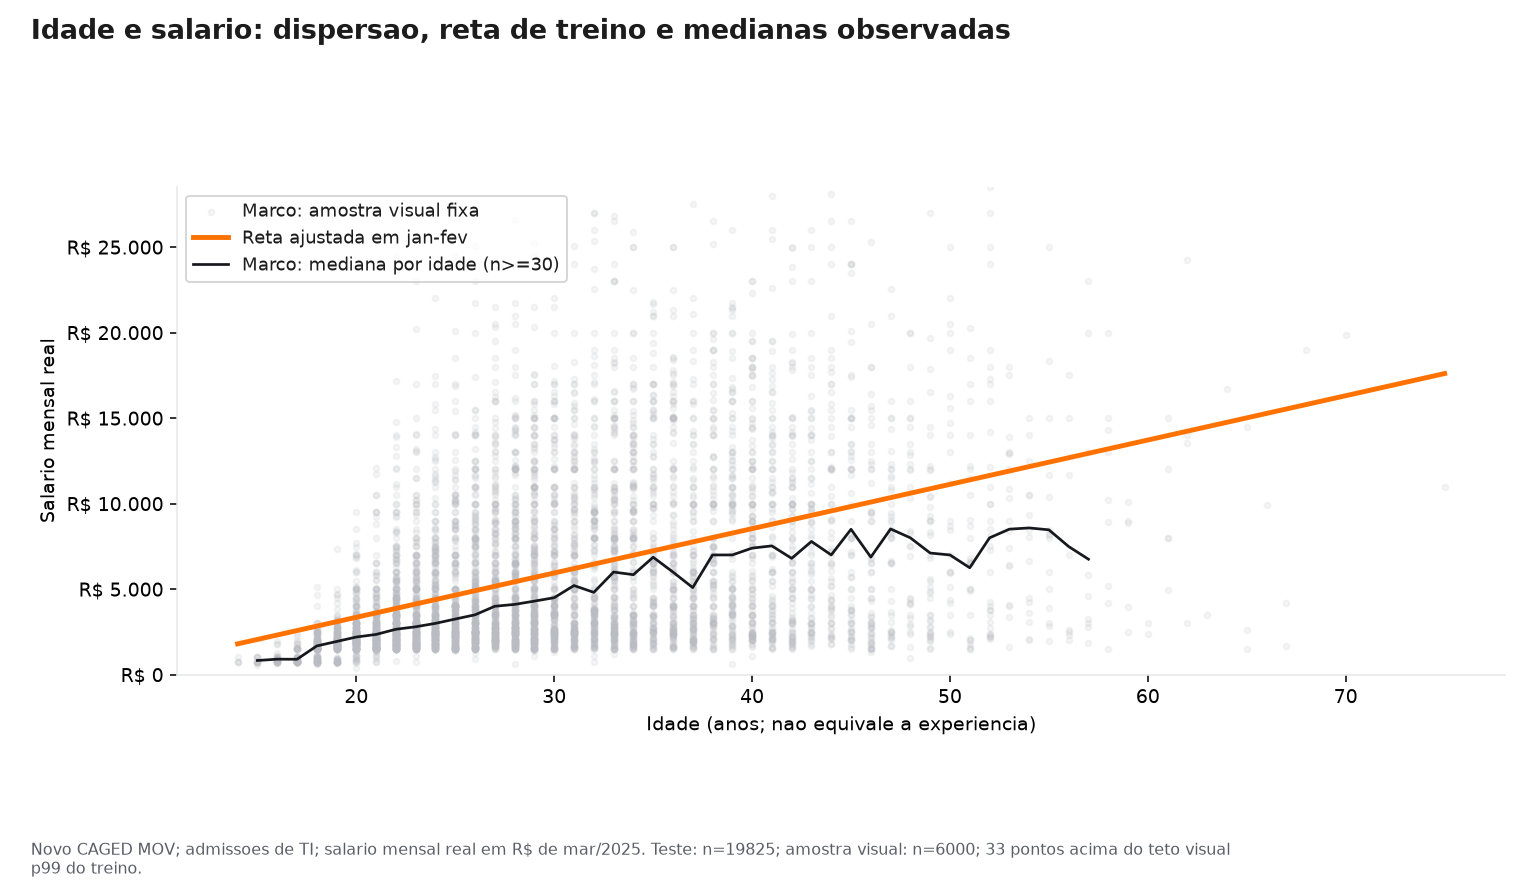

### Interpretacao

A reta simples ajustada em jan-fev varia R$ 259 por ano de idade. Isso e associacao marginal, nao efeito causal, experiencia profissional ou crescimento individual. A mediana por idade em marco nao e a reta OLS, que aproxima a media condicional sob especificacao linear. O teto do grafico e o p99 do salario do treino; 33 dos 6000 pontos da amostra visual ficam acima dele. Todos os registros entram nas metricas e nos residuos.

In [5]:
resultado = analise.run('R2')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas. CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

## R3. Salarios observados versus previstos

### Cobertura visual

,modelo,n_total,fora_janela_p99_treino
0,idade,19825,173
1,multipla,19825,186


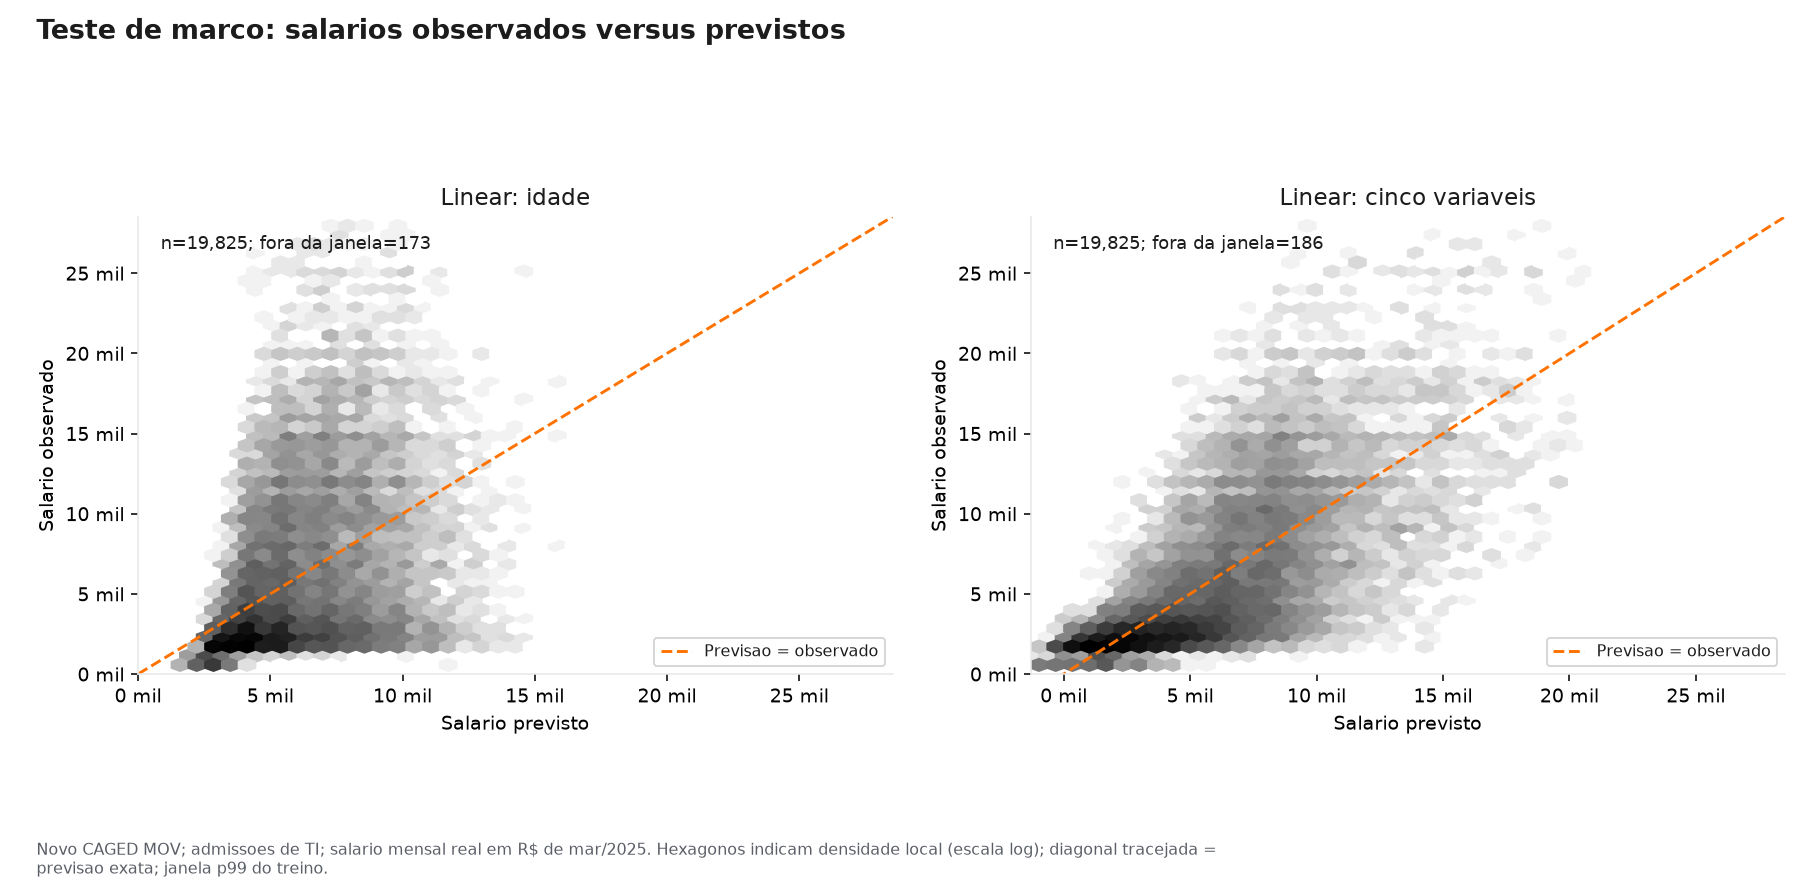

### Interpretacao

A diagonal representa previsao exata. Concentracao sistematica acima da diagonal indica subestimacao. O grafico compara os dois regressores, sem escolher pelo teste; usa densidade em hexagonos e janela limitada pelo p99 do treino nos dois eixos. O numero fora da janela e informado por modelo, sem exclui-lo da avaliacao. A regressao linear pode comprimir a dispersao e errar salarios altos: ela nao fornece um intervalo salarial individual confiavel.

In [6]:
resultado = analise.run('R3')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas. CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

## R4. Residuos e variacao nao explicada

### Residuos marco

,modelo,n,p10_residuo,mediana_residuo,p90_residuo,media_residuo,minimo,maximo
0,multipla,19825,-3856.4393,-319.9873,4312.1451,70.1329,-35592.2778,93314.7008


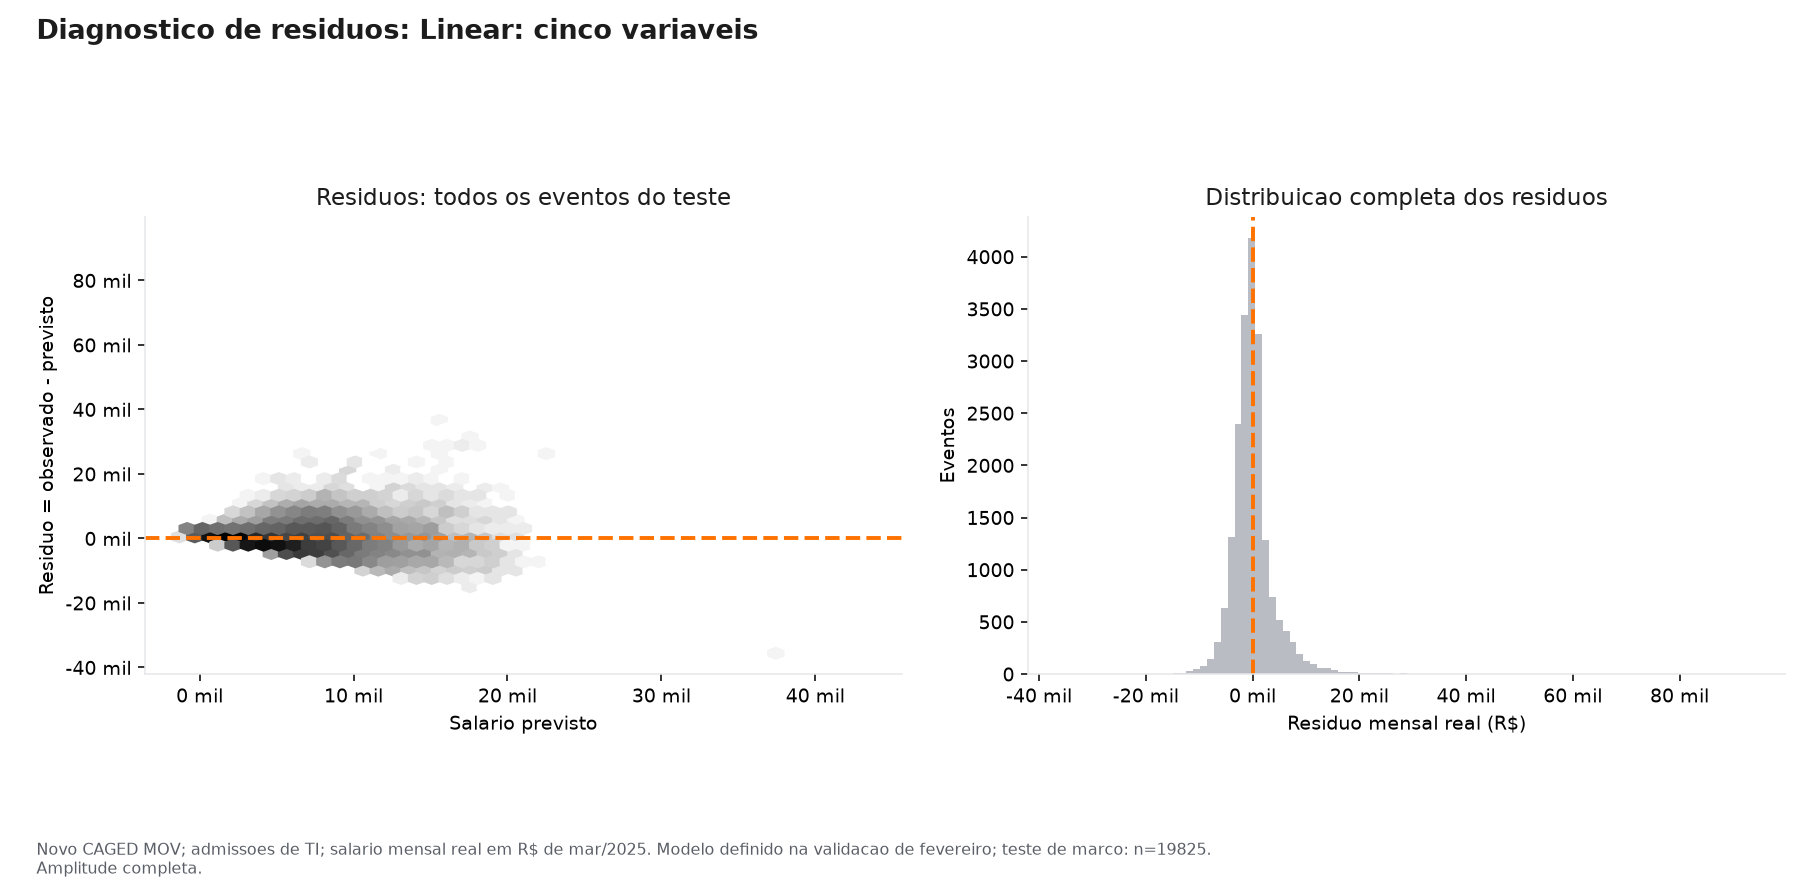

### Interpretacao

Para Linear: cinco variaveis, o residuo observado-previsto tem mediana R$ -320, p10 R$ -3.856 e p90 R$ 4.312. Residuo positivo significa subestimacao; negativo, superestimacao. Ambos os paineis incluem a amplitude completa, sem corte de cauda. Assimetria, caudas e variacao da dispersao indicam limites da aproximacao linear; nao se presume normalidade, homocedasticidade ou independencia entre eventos. Nao foram calculados p-valores, intervalos de confianca ou de previsao.

In [7]:
resultado = analise.run('R4')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas. CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

## R5. Comparacao com a mediana do treino

### Comparacao teste

,modelo,n,mae,rmse,r2,mediana_erro_absoluto,residuo_medio,previsoes_negativas,ganho_mae_vs_mediana_pct
0,mediana,19825,3734.2331,6429.8952,-0.1679,1732.4009,2438.2029,0,0.0000
1,idade,19825,3603.4857,5479.4255,0.1518,2472.3327,20.6986,0,3.5013
2,multipla,19825,2666.7699,4306.9503,0.4760,1719.2544,70.1329,255,28.5859


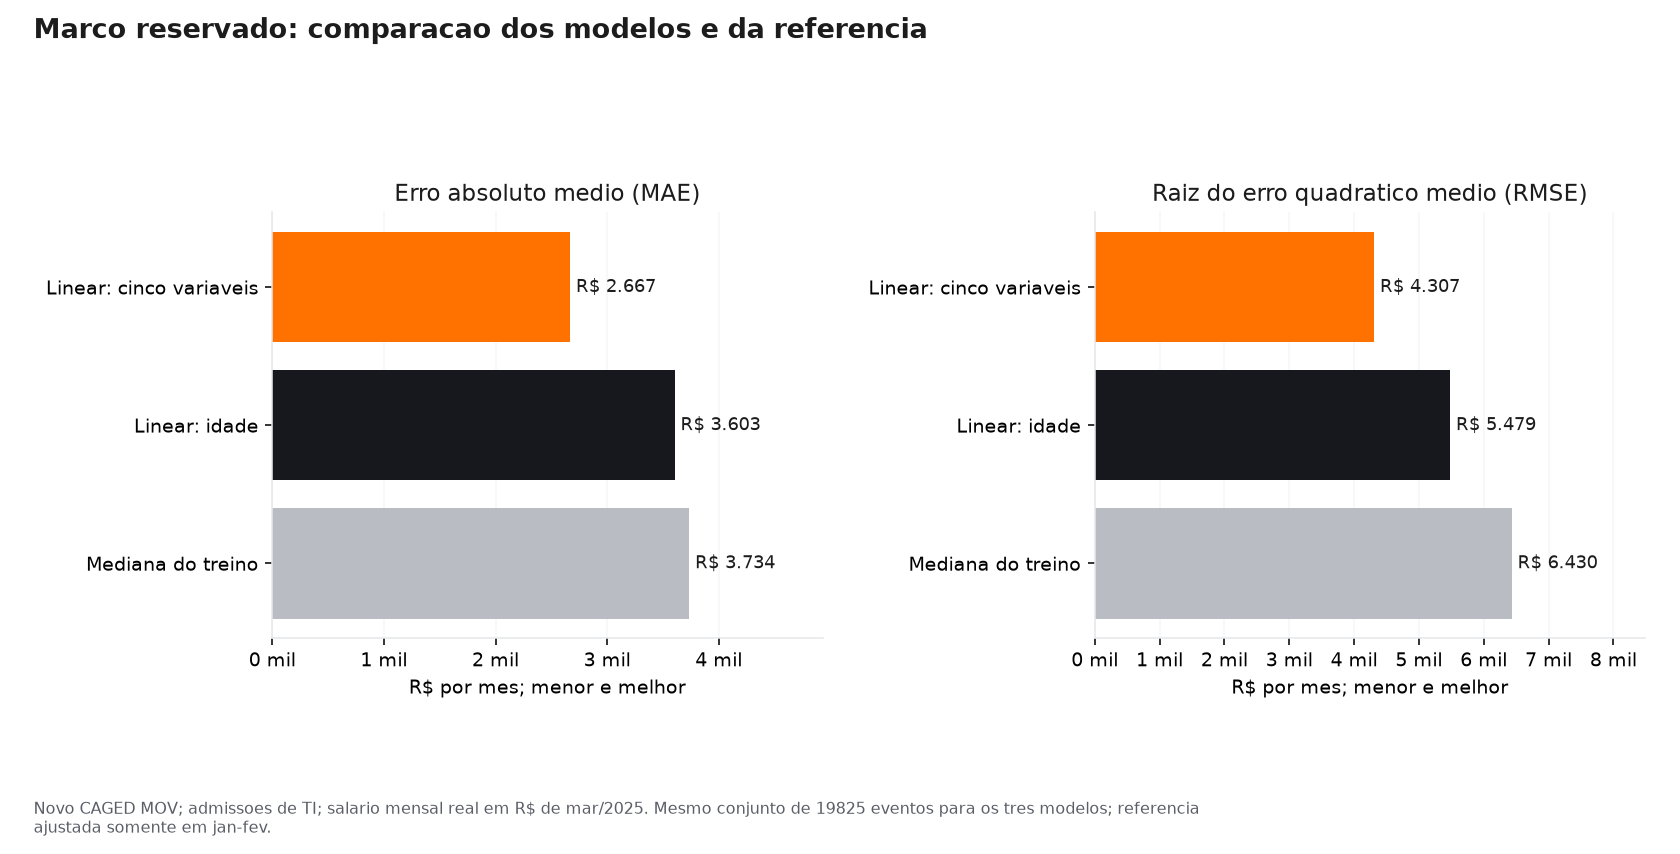

### Interpretacao

No teste, a mediana do treino tem MAE R$ 3.734; o modelo previamente escolhido tem MAE R$ 2.667, variacao de 28.6% em relacao a referencia (positivo = reducao). Seu RMSE e R$ 4.307, metrica mais sensivel a erros extremos. Foram geradas 255 previsoes negativas (1.3% do teste), valores sem sentido salarial, mantidos para expor o limite da forma linear. Isso impede tratar a melhoria global como validacao de uma calculadora salarial individual; nenhum valor foi corrigido apos olhar o teste. A tabela inclui R2 e erro absoluto mediano. Desempenho em um unico mes nao demonstra generalizacao para 2026 ou outros mercados. Nao houve reescolha de modelo a partir deste grafico.

In [8]:
resultado = analise.run('R5')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas. CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

## R6. Desempenho por regiao, UF e area de TI

### Metricas recortes

,dimensao,grupo,modelo,n,suficiente,mae,rmse,r2,mediana_erro_absoluto,residuo_medio,previsoes_negativas
0,recorte,Brasil,mediana,19825,True,3734.2331,6429.8952,-0.1679,1732.4009,2438.2029,0.0
1,recorte,Brasil,idade,19825,True,3603.4857,5479.4255,0.1518,2472.3327,20.6986,0.0
2,recorte,Brasil,multipla,19825,True,2666.7699,4306.9503,0.4760,1719.2544,70.1329,255.0
3,recorte,Nordeste,mediana,1937,True,2229.7839,3259.1664,-0.0001,1799.6009,35.3819,0.0
4,recorte,Nordeste,idade,1937,True,3206.9525,3951.2734,-0.4700,2614.2911,-2165.3891,0.0
5,recorte,Nordeste,multipla,1937,True,1934.7131,2702.5544,0.3123,1460.4090,-137.0917,136.0
6,recorte,Pernambuco,mediana,399,True,2785.8514,4293.3943,-0.0965,1684.0009,1273.9263,0.0
7,recorte,Pernambuco,idade,399,True,3261.4491,4235.8180,-0.0673,2614.2911,-1161.7544,0.0
8,recorte,Pernambuco,multipla,399,True,2299.1926,3394.0066,0.3148,1589.4100,93.0173,12.0
9,uf_sigla,AC,mediana,14,False,NaN,NaN,NaN,NaN,NaN,NaN


Exibidas 18 de 120 linhas. CSV completo em resultados/tabelas.

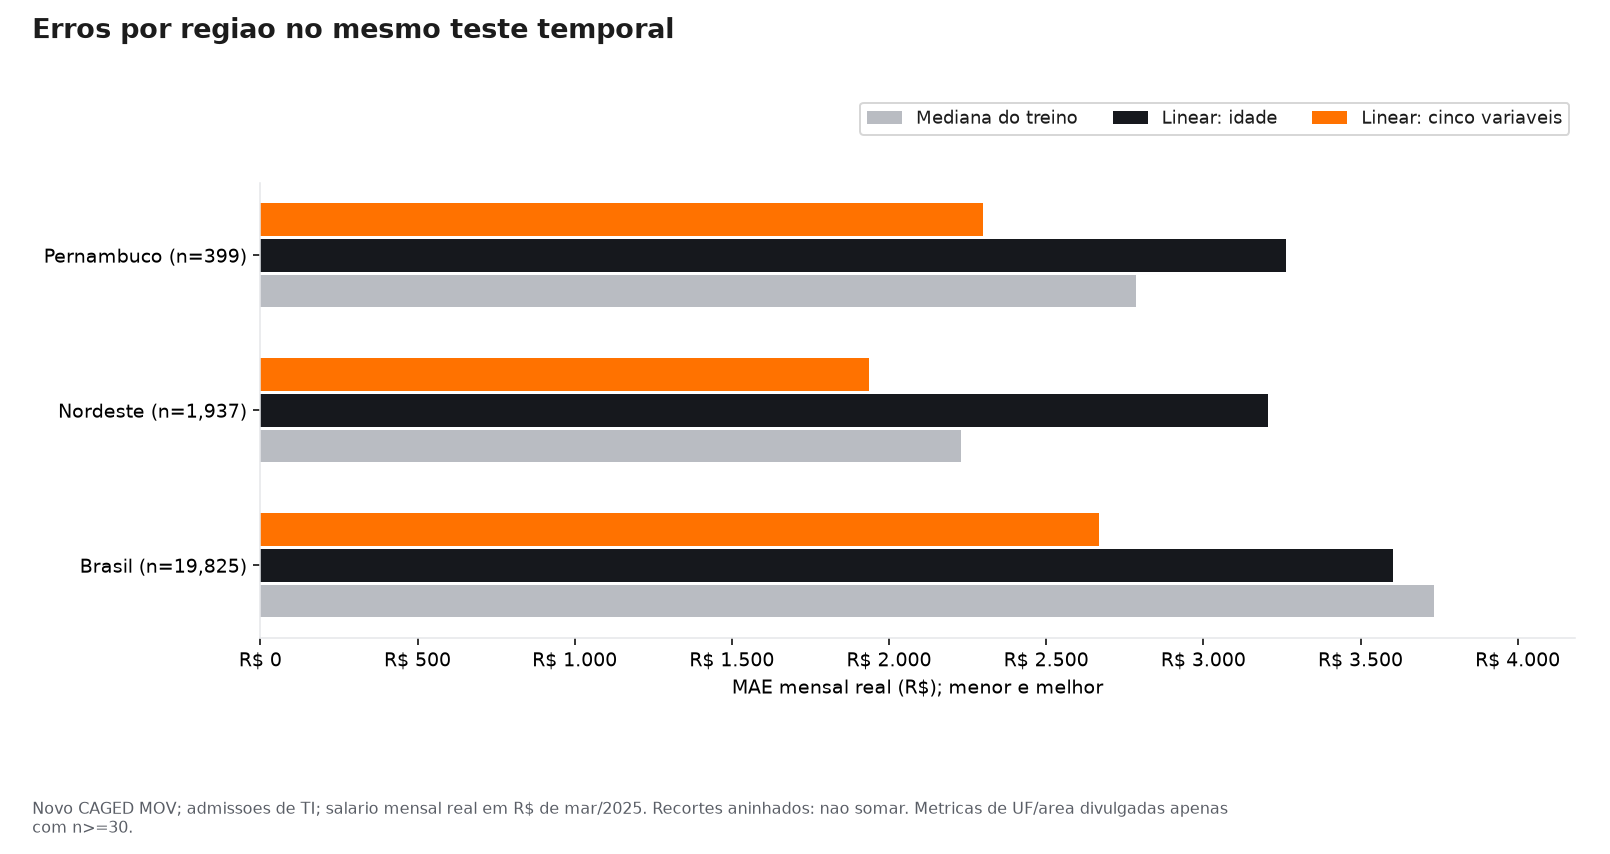

### Interpretacao

Em Pernambuco, o modelo escolhido tem MAE R$ 2.299 em 399 admissoes de marco. Ha 3 recortes UF/area com n<30 e metricas suprimidas (o n permanece). A referencia usada por regiao continua sendo a mediana global do treino, nao uma mediana local recalculada no teste. Brasil, Nordeste e PE sao recortes aninhados e nao devem ser somados. Diferencas refletem composicao de cargos e salarios; nao constituem auditoria de equidade nem avaliacao individual. Tabelas completas por UF e area acompanham o notebook.

In [9]:
resultado = analise.run('R6')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas. CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

## R7. Calibracao descritiva no teste

### Calibracao descritiva

,faixa_previsao,n,previsto_medio,observado_medio,observado_p10,observado_p90,residuo_medio
0,"(-1311.302, 1413.728]",1984,684.9840,1798.1791,828.270,2504.865,1113.1951
1,"(1413.728, 2413.907]",1981,1915.7274,2212.5093,1487.230,3200.000,296.7819
2,"(2413.907, 3338.451]",1984,2868.7084,2737.5590,1578.531,4206.290,-131.1494
3,"(3338.451, 4323.583]",1990,3836.2799,3328.7152,1698.831,5885.100,-507.5648
4,"(4323.583, 5248.959]",1975,4773.6854,4231.4722,1950.000,8000.000,-542.2131
5,"(5248.959, 6296.598]",2003,5793.9301,5255.7120,2122.032,10360.298,-538.2181
6,"(6296.598, 7411.488]",1966,6811.3571,6850.4146,2500.000,13000.000,39.0576
7,"(7411.488, 8680.761]",2008,8042.2270,8090.2601,3000.000,14406.500,48.0331
8,"(8680.761, 10981.814]",1951,9645.5727,10034.6382,3600.000,16640.000,389.0655
9,"(10981.814, 43395.322]",1983,14549.4682,15094.4766,6000.000,25833.330,545.0084


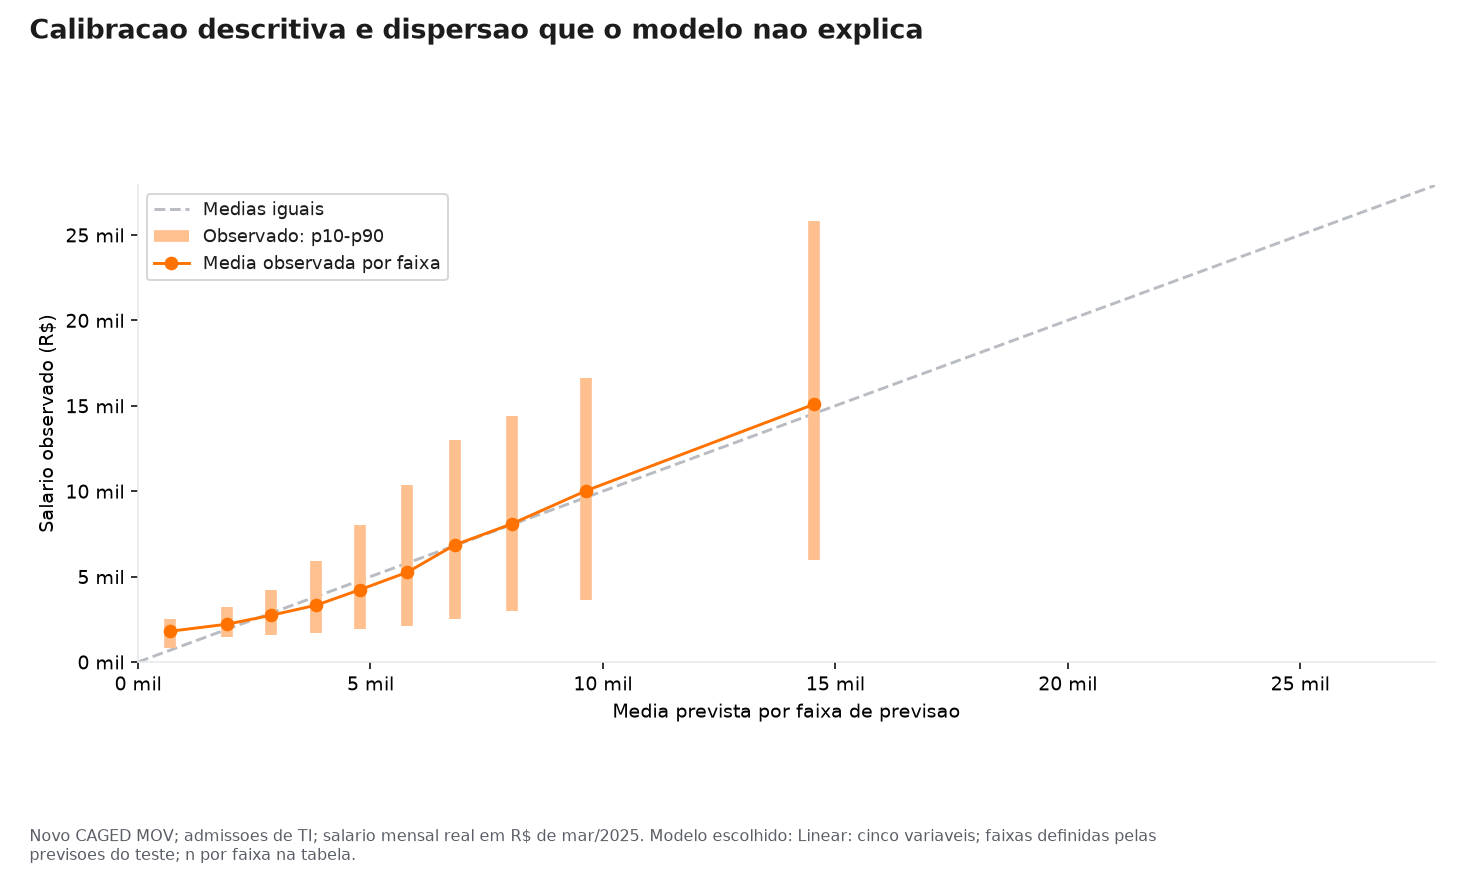

### Interpretacao

As faixas usam os quantis das previsoes de marco apenas para diagnostico, sem novo ajuste ou calibracao. A curva aproxima medias previstas e observadas; as faixas verticais sao p10-p90 dos salarios observados, nao intervalos de confianca/previsao. Distancia da diagonal revela erro medio sistematico; a largura da faixa mostra variacao de salarios entre eventos com previsoes semelhantes. Nao se recomenda esse modelo como calculadora salarial pessoal.

In [10]:
resultado = analise.run('R7')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas. CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

## R8. Sensibilidade a cauda e categorias novas

In [11]:
resultado = analise.run('R8')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas. CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

### Sensibilidade cauda

,recorte,modelo,n,mae,rmse,r2,mediana_erro_absoluto,residuo_medio,previsoes_negativas
0,Todos (avaliacao principal),mediana,19825,3734.2331,6429.8952,-0.1679,1732.4009,2438.2029,0
1,Todos (avaliacao principal),idade,19825,3603.4857,5479.4255,0.1518,2472.3327,20.6986,0
2,Todos (avaliacao principal),multipla,19825,2666.7699,4306.9503,0.4760,1719.2544,70.1329,255
3,Salario <= p99 do treino,mediana,19652,3451.2905,5377.3594,-0.1890,1719.6009,2143.8511,0
4,Salario <= p99 do treino,idade,19652,3363.0906,4517.6256,0.1608,2446.1894,-251.2364,0
5,Salario <= p99 do treino,multipla,19652,2491.2995,3563.1252,0.4780,1696.9784,-125.2188,255
6,Salario > p99 do treino,mediana,173,35875.2093,38118.9799,-7.7520,30980.3991,35875.2093,0
7,Salario > p99 do treino,idade,173,30911.2601,33500.1806,-5.7596,26426.0139,30911.2601,0
8,Salario > p99 do treino,multipla,173,22599.3919,26144.4561,-3.1170,19985.4263,22261.1779,0


### Categorias novas teste

,variavel,n_categoria_nao_vista_treino,n_teste
0,cbo_codigo,0,19825
1,uf_sigla,0,19825
2,grau_instrucao,0,19825


### Interpretacao

O limiar p99 foi fixado no treino (R$ 28.526). Na cauda acima dele ha 173 eventos, com MAE R$ 22.599, contra R$ 2.491 abaixo/igual ao limiar. Esta e uma analise de sensibilidade por salario observado, nao um filtro de producao: o alvo futuro nao estaria disponivel para decidir a faixa. A avaliacao principal mantem todos os salarios validos e nao usa winsorizacao ou remocao de outliers baseada em marco. Categorias novas sao codificadas com zeros pelo encoder; a tabela informa sua cobertura. Os coeficientes sao descritivos: numericas estao padronizadas e categorias usam one-hot completo com Ridge, sem categoria-base omitida. Nao sao retornos causais da escolaridade, premios salariais individuais ou medidas de significancia.

## Conclusão e uso responsável

A síntese a seguir é calculada a partir desta execução. Não há inferência causal, intervalos individuais, acompanhamento de vínculos ou previsão de carreira. Os erros refletem apenas um mês de avaliação. Não foram retirados salários válidos para melhorar as métricas.

Gráficos e tabelas agregados são versionáveis; o extrato linha a linha de previsões fica local, ignorado pelo Git. Os códigos da etapa 03, os datasets e o aplicativo existente não são modificados pelo runner. A classificação supervisionada pertence à etapa 05, ainda pendente.

In [12]:
analise.summary()
display(Markdown((AREA / 'sintese_achados.md').read_text(encoding='utf-8')))
display(Markdown('Execucao concluida. Tabelas completas e auditoria em resultados/.'))

# Sintese da regressao salarial

Etapa 04. Radar de Carreira em TI. Execucao com CAGED MOV de jan-mar/2025.

Somente fontes publicas; sem State of Data ou pesquisa G12. Valores mensais a precos de marco/2025.

## R0

Dos 118.564 movimentos, ha 61.047 admissoes. A modelagem usa 60.862 salarios validos; 185 salarios sinalizados ficam fora desta tarefa, sem alterar a fonte. Treino final: 41.037 eventos de jan-fev; teste final: 19.825 de marco. Idade e horas invalidas viram ausentes nas entradas, sem excluir eventos; imputacao, escala e categorias sao ajustadas somente no treino. Linhas de eventos semelhantes sao preservadas: nao existe identificador de pessoa/vinculo. Nenhum dado de State of Data ou G12 entra nesta etapa.

## R1

A validacao jan->fev escolheu **Linear: cinco variaveis**, antes do teste. Todos os modelos foram depois reajustados em jan-fev. Em marco, o modelo escolhido tem MAE R$ 2.667, RMSE R$ 4.307 e R2=0.476. A referencia constante usa apenas a mediana de jan-fev (R$ 3.520). MAE foi definido para a escolha; a mediana minimiza erro absoluto, nao erro quadratico. A regressao simples usa idade; a multipla e linear com penalizacao Ridge fixa alpha=10, sem busca de hiperparametros. Março nao ajusta imputacao, escalas, categorias, coeficientes, alpha ou escolha de modelo. Previsoes negativas, se houver, nao sao recortadas.

## R2

A reta simples ajustada em jan-fev varia R$ 259 por ano de idade. Isso e associacao marginal, nao efeito causal, experiencia profissional ou crescimento individual. A mediana por idade em marco nao e a reta OLS, que aproxima a media condicional sob especificacao linear. O teto do grafico e o p99 do salario do treino; 33 dos 6000 pontos da amostra visual ficam acima dele. Todos os registros entram nas metricas e nos residuos.

## R3

A diagonal representa previsao exata. Concentracao sistematica acima da diagonal indica subestimacao. O grafico compara os dois regressores, sem escolher pelo teste; usa densidade em hexagonos e janela limitada pelo p99 do treino nos dois eixos. O numero fora da janela e informado por modelo, sem exclui-lo da avaliacao. A regressao linear pode comprimir a dispersao e errar salarios altos: ela nao fornece um intervalo salarial individual confiavel.

## R4

Para Linear: cinco variaveis, o residuo observado-previsto tem mediana R$ -320, p10 R$ -3.856 e p90 R$ 4.312. Residuo positivo significa subestimacao; negativo, superestimacao. Ambos os paineis incluem a amplitude completa, sem corte de cauda. Assimetria, caudas e variacao da dispersao indicam limites da aproximacao linear; nao se presume normalidade, homocedasticidade ou independencia entre eventos. Nao foram calculados p-valores, intervalos de confianca ou de previsao.

## R5

No teste, a mediana do treino tem MAE R$ 3.734; o modelo previamente escolhido tem MAE R$ 2.667, variacao de 28.6% em relacao a referencia (positivo = reducao). Seu RMSE e R$ 4.307, metrica mais sensivel a erros extremos. Foram geradas 255 previsoes negativas (1.3% do teste), valores sem sentido salarial, mantidos para expor o limite da forma linear. Isso impede tratar a melhoria global como validacao de uma calculadora salarial individual; nenhum valor foi corrigido apos olhar o teste. A tabela inclui R2 e erro absoluto mediano. Desempenho em um unico mes nao demonstra generalizacao para 2026 ou outros mercados. Nao houve reescolha de modelo a partir deste grafico.

## R6

Em Pernambuco, o modelo escolhido tem MAE R$ 2.299 em 399 admissoes de marco. Ha 3 recortes UF/area com n<30 e metricas suprimidas (o n permanece). A referencia usada por regiao continua sendo a mediana global do treino, nao uma mediana local recalculada no teste. Brasil, Nordeste e PE sao recortes aninhados e nao devem ser somados. Diferencas refletem composicao de cargos e salarios; nao constituem auditoria de equidade nem avaliacao individual. Tabelas completas por UF e area acompanham o notebook.

## R7

As faixas usam os quantis das previsoes de marco apenas para diagnostico, sem novo ajuste ou calibracao. A curva aproxima medias previstas e observadas; as faixas verticais sao p10-p90 dos salarios observados, nao intervalos de confianca/previsao. Distancia da diagonal revela erro medio sistematico; a largura da faixa mostra variacao de salarios entre eventos com previsoes semelhantes. Nao se recomenda esse modelo como calculadora salarial pessoal.

## R8

O limiar p99 foi fixado no treino (R$ 28.526). Na cauda acima dele ha 173 eventos, com MAE R$ 22.599, contra R$ 2.491 abaixo/igual ao limiar. Esta e uma analise de sensibilidade por salario observado, nao um filtro de producao: o alvo futuro nao estaria disponivel para decidir a faixa. A avaliacao principal mantem todos os salarios validos e nao usa winsorizacao ou remocao de outliers baseada em marco. Categorias novas sao codificadas com zeros pelo encoder; a tabela informa sua cobertura. Os coeficientes sao descritivos: numericas estao padronizadas e categorias usam one-hot completo com Ridge, sem categoria-base omitida. Nao sao retornos causais da escolaridade, premios salariais individuais ou medidas de significancia.

## Limites e proximo passo

Estudo observacional de movimentacoes, nao pessoas ou vinculos. Apenas um mes reservado para teste; nao permite previsao de longo prazo ou inferencia causal. Nao identifica senioridade, habilidades, tempo de vinculo ou evolucao individual. A exposicao da fonte e real de mar/2025 (IPCA comum), nao informacao de salario atual de 2026. Sexo e raca/cor nao entram; isso nao elimina vieses ou proxies. A etapa 05 continua pendente e usa outra fonte/alvo.


Execucao concluida. Tabelas completas e auditoria em resultados/.